In [1]:
import pandas as pd
import numpy as np

# 读取数据
df = pd.read_csv('UserBehavior.csv', 
                 header=None,
                 names=['用户ID', '商品ID', '类目ID', '行为类型', '时间戳'],
                 nrows=100000)

df.head()



,用户ID,商品ID,类目ID,行为类型,时间戳
0,1,2268318,2520377,pv,1511544070
1,1,2333346,2520771,pv,1511561733
2,1,2576651,149192,pv,1511572885
3,1,3830808,4181361,pv,1511593493
4,1,4365585,2520377,pv,1511596146


In [2]:
# 查看数据形状
df.shape

# 查看每列的数据类型
df.dtypes

# 查看空值情况
df.isnull().sum()
# 行为类型有哪些
df['行为类型'].unique()

# 各行为类型的数量
df['行为类型'].value_counts()

行为类型
pv      89709
cart     5446
fav      2744
buy      2101
Name: count, dtype: int64

In [3]:
# 1. 把时间戳转成正常日期格式
df['日期'] = pd.to_datetime(df['时间戳'], unit='s')

# 2. 提取日期、小时、周几等字段（方便后续分析）
df['日期_年月日'] = df['日期'].dt.date
df['小时'] = df['日期'].dt.hour
df['周几'] = df['日期'].dt.dayofweek  # 0=周一, 6=周日

# 3. 查看处理后的前几行
df.head()

,用户ID,商品ID,类目ID,行为类型,时间戳,日期,日期_年月日,小时,周几
0,1,2268318,2520377,pv,1511544070,2017-11-24 17:21:10,2017-11-24,17,4
1,1,2333346,2520771,pv,1511561733,2017-11-24 22:15:33,2017-11-24,22,4
2,1,2576651,149192,pv,1511572885,2017-11-25 01:21:25,2017-11-25,1,5
3,1,3830808,4181361,pv,1511593493,2017-11-25 07:04:53,2017-11-25,7,5
4,1,4365585,2520377,pv,1511596146,2017-11-25 07:49:06,2017-11-25,7,5


In [4]:
# 查看数据的时间范围
print('数据起始日期:', df['日期_年月日'].min())
print('数据结束日期:', df['日期_年月日'].max())
print('共', df['日期_年月日'].nunique(), '天数据')

# 查看有哪些行为类型
df['行为类型'].unique()

数据起始日期: 2017-09-11
数据结束日期: 2017-12-03
共 15 天数据


<StringArray>
['pv', 'fav', 'buy', 'cart']
Length: 4, dtype: str

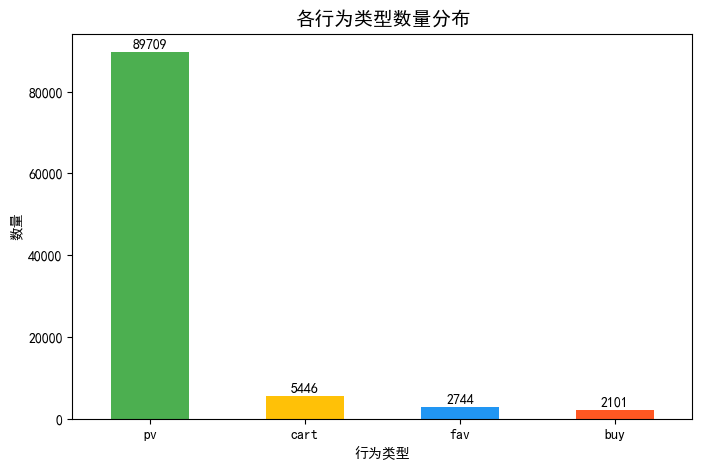

In [5]:
import matplotlib.pyplot as plt
# 适配Windows系统
plt.rcParams["font.family"] = ["SimHei", "Microsoft YaHei"]
# 解决负号显示异常（配套中文设置）
plt.rcParams["axes.unicode_minus"] = False
import matplotlib.pyplot as plt

# 统计各行为类型的数量
behavior_count = df['行为类型'].value_counts()

# 画柱状图
plt.figure(figsize=(8, 5))
behavior_count.plot(kind='bar', color=['#4CAF50', '#FFC107', '#2196F3', '#FF5722'])
plt.title('各行为类型数量分布', fontsize=14)
plt.xlabel('行为类型')
plt.ylabel('数量')
plt.xticks(rotation=0)
for i, v in enumerate(behavior_count):
    plt.text(i, v + 500, str(v), ha='center', va='bottom')
plt.savefig('行为类型分布.png', dpi=300, bbox_inches='tight')
plt.show()

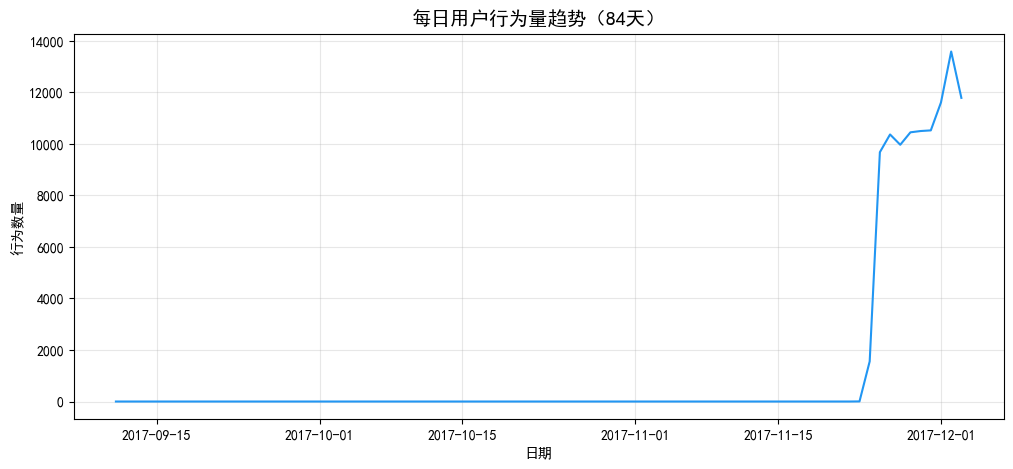

In [6]:
# 按天统计总行为数
daily_activity = df.groupby('日期_年月日').size()

plt.figure(figsize=(12, 5))
daily_activity.plot(kind='line', color='#2196F3')
plt.title('每日用户行为量趋势（84天）', fontsize=14)
plt.xlabel('日期')
plt.ylabel('行为数量')
plt.grid(True, alpha=0.3)
plt.savefig('每日用户活跃趋势.png', dpi=300, bbox_inches='tight')
plt.show()

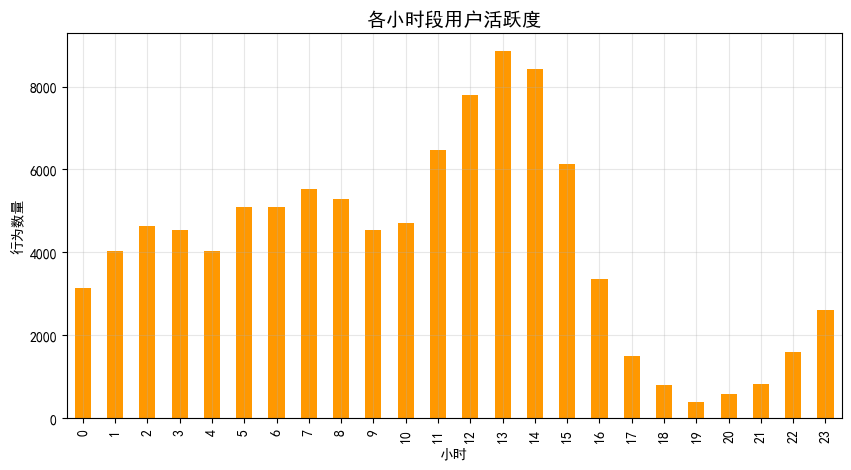

In [7]:
# 按小时统计行为量
hourly_activity = df.groupby('小时').size()

plt.figure(figsize=(10, 5))
hourly_activity.plot(kind='bar', color='#FF9800')
plt.title('各小时段用户活跃度', fontsize=14)
plt.xlabel('小时')
plt.ylabel('行为数量')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.savefig('各小时段活跃度分布.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# 计算各行为类型的独立用户数
pv_users = df[df['行为类型'] == 'pv']['用户ID'].nunique()
fav_users = df[df['行为类型'] == 'fav']['用户ID'].nunique()
cart_users = df[df['行为类型'] == 'cart']['用户ID'].nunique()
buy_users = df[df['行为类型'] == 'buy']['用户ID'].nunique()

print('===== 用户行为转化漏斗 =====')
print(f'浏览用户数: {pv_users}')
print(f'收藏用户数: {fav_users}')
print(f'加购用户数: {cart_users}')
print(f'购买用户数: {buy_users}')
print(f'\n浏览→购买转化率: {buy_users/pv_users*100:.2f}%')
print(f'浏览→加购转化率: {cart_users/pv_users*100:.2f}%')
print(f'加购→购买转化率: {buy_users/cart_users*100:.2f}%' if cart_users > 0 else '加购用户数为0')

===== 用户行为转化漏斗 =====
浏览用户数: 980
收藏用户数: 363
加购用户数: 723
购买用户数: 671

浏览→购买转化率: 68.47%
浏览→加购转化率: 73.78%
加购→购买转化率: 92.81%


In [9]:
# 统计每个用户的总行为次数
user_activity = df.groupby('用户ID').size().reset_index(name='行为次数')

# 查看用户行为次数的分布情况
print('===== 用户行为次数分布 =====')
print(user_activity['行为次数'].describe())

# 查看最高活跃用户的行为次数
print(f'\n最活跃用户的行为次数: {user_activity["行为次数"].max()}')

===== 用户行为次数分布 =====
count    983.000000
mean     101.729400
std       90.647467
min        4.000000
25%       37.500000
50%       74.000000
75%      136.000000
max      539.000000
Name: 行为次数, dtype: float64

最活跃用户的行为次数: 539


In [10]:
# 根据数据分布调整分层标准
def get_user_level(count):
    if count <= 20:
        return '低频用户'
    elif count <= 74:  # 中位数
        return '中频用户'
    elif count <= 150:
        return '高频用户'
    else:
        return '超级用户'

user_activity['用户层级'] = user_activity['行为次数'].apply(get_user_level)

# 查看各层级的用户数量
level_counts = user_activity['用户层级'].value_counts()
print('===== 各层级用户数量 =====')
print(level_counts)
print(f'\n各层级占比:')
print(level_counts / len(user_activity) * 100)

===== 各层级用户数量 =====
用户层级
中频用户    378
高频用户    280
超级用户    210
低频用户    115
Name: count, dtype: int64

各层级占比:
用户层级
中频用户    38.453713
高频用户    28.484232
超级用户    21.363174
低频用户    11.698881
Name: count, dtype: float64


In [11]:
# 1. 先给每个用户打上"是否购买"的标签
buy_users_set = set(df[df['行为类型'] == 'buy']['用户ID'].unique())
user_activity['是否购买'] = user_activity['用户ID'].apply(lambda x: '购买' if x in buy_users_set else '未购买')

# 2. 按层级统计转化率
level_buy_rate = user_activity.groupby('用户层级').apply(
    lambda x: (x['是否购买'] == '购买').sum() / len(x) * 100
).reset_index(name='购买转化率(%)')

print('===== 各层级用户购买转化率 =====')
print(level_buy_rate)

===== 各层级用户购买转化率 =====
   用户层级   购买转化率(%)
0  中频用户  61.640212
1  低频用户  47.826087
2  超级用户  80.952381
3  高频用户  76.071429


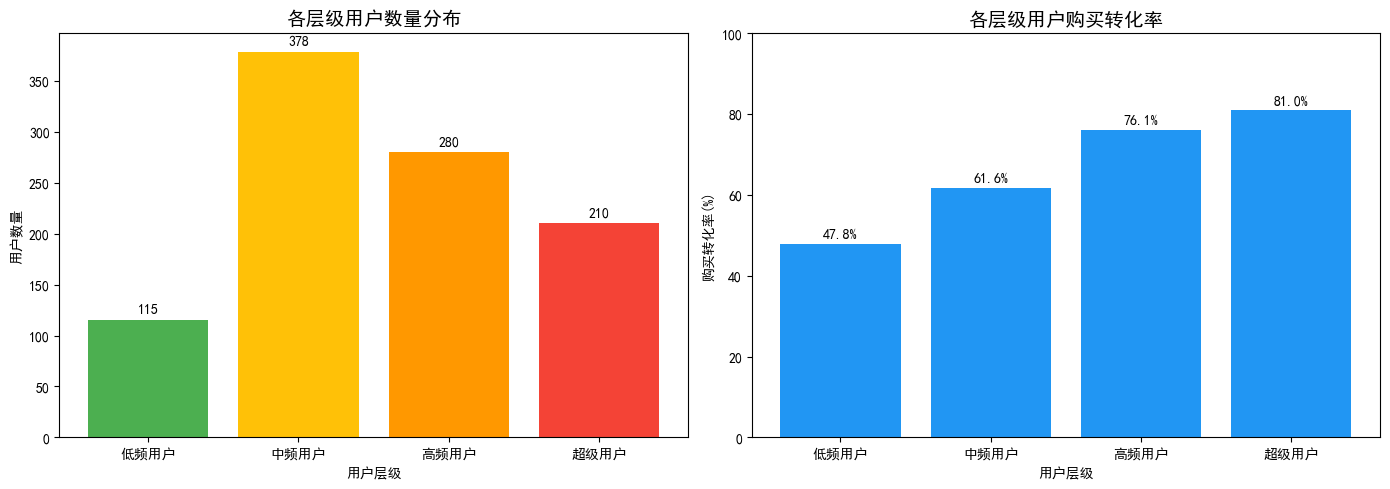

In [12]:
import matplotlib.pyplot as plt

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 按层级顺序排序
level_order = ['低频用户', '中频用户', '高频用户', '超级用户']
level_buy_rate['用户层级'] = pd.Categorical(level_buy_rate['用户层级'], categories=level_order, ordered=True)
level_buy_rate = level_buy_rate.sort_values('用户层级')

# 画图
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左图：各层级用户数量
level_counts_sorted = level_counts.reindex(level_order)
colors = ['#4CAF50', '#FFC107', '#FF9800', '#F44336']
axes[0].bar(level_counts_sorted.index, level_counts_sorted.values, color=colors)
axes[0].set_title('各层级用户数量分布', fontsize=14)
axes[0].set_xlabel('用户层级')
axes[0].set_ylabel('用户数量')
for i, v in enumerate(level_counts_sorted.values):
    axes[0].text(i, v + 5, str(v), ha='center', va='bottom')

# 右图：各层级购买转化率
axes[1].bar(level_buy_rate['用户层级'], level_buy_rate['购买转化率(%)'], color='#2196F3')
axes[1].set_title('各层级用户购买转化率', fontsize=14)
axes[1].set_xlabel('用户层级')
axes[1].set_ylabel('购买转化率(%)')
axes[1].set_ylim(0, 100)
for i, v in enumerate(level_buy_rate['购买转化率(%)']):
    axes[1].text(i, v + 1, f'{v:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.savefig('用户分层分析.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
# 找出超级用户（行为次数>=150次的用户，根据分层标准）
super_users = user_activity[user_activity['用户层级'] == '超级用户']['用户ID'].tolist()

# 超级用户行为分布
super_user_data = df[df['用户ID'].isin(super_users)]
super_behavior = super_user_data['行为类型'].value_counts()

print('===== 超级用户行为特征 =====')
print(f'超级用户数量: {len(super_users)}')
print(f'\n超级用户行为分布:')
print(super_behavior)
print(f'\n超级用户人均行为次数: {super_user_data.groupby("用户ID").size().mean():.1f}')

# 普通用户（非超级用户）对比
normal_users = [u for u in df['用户ID'].unique() if u not in super_users]
normal_user_data = df[df['用户ID'].isin(normal_users)]
normal_behavior = normal_user_data['行为类型'].value_counts()

print('\n===== 普通用户行为分布 =====')
print(normal_behavior)
print(f'\n普通用户人均行为次数: {normal_user_data.groupby("用户ID").size().mean():.1f}')

===== 超级用户行为特征 =====
超级用户数量: 210

超级用户行为分布:
行为类型
pv      46085
cart     2528
fav      1524
buy       728
Name: count, dtype: int64

超级用户人均行为次数: 242.2

===== 普通用户行为分布 =====
行为类型
pv      43624
cart     2918
buy      1373
fav      1220
Name: count, dtype: int64

普通用户人均行为次数: 63.6
